# Vitamin D Prediction: Exploratory Analysis and Model Evaluation

This notebook follows the structure of the original `vitaminD_simple.ipynb`: dataset review, cleaning, exploratory visualizations, correlation analysis, model comparison, and prediction diagnostics. It is adapted to the production pipeline in this project.

> **Data limitation:** this is a custom dataset copied from the previous project. Its source does not document whether it is synthetic. Results are useful for demonstrating the workflow, but do **not** establish real-world or clinical accuracy.

In [1]:
from pathlib import Path
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

def find_project_root(start: Path) -> Path:
    """Locate the project folder from the kernel working directory."""
    for candidate in (start.resolve(), *start.resolve().parents):
        has_data = (candidate / 'data' / 'VitaminD_Dataset.csv').is_file()
        has_preprocessing = (candidate / 'src' / 'preprocessing.py').is_file()
        if has_data and has_preprocessing:
            return candidate
    raise FileNotFoundError(
        'Could not find the project root. Expected data/VitaminD_Dataset.csv and src/preprocessing.py.'
    )

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.preprocessing import RANDOM_STATE, TARGET_COLUMN, build_preprocessor, load_dataset, split_features_target
from src.train import build_models

sns.set_theme(style='whitegrid', context='notebook')
DATA_PATH = PROJECT_ROOT / 'data' / 'VitaminD_Dataset.csv'
METRICS_PATH = PROJECT_ROOT / 'reports' / 'model_metrics.csv'
PREDICTIONS_PATH = PROJECT_ROOT / 'reports' / 'holdout_predictions.csv'
MODEL_PATH = PROJECT_ROOT / 'models' / 'vitamin_d_pipeline.joblib'
METADATA_PATH = PROJECT_ROOT / 'models' / 'metadata.json'
print(f'Project root: {PROJECT_ROOT}')
print(f'Random seed: {RANDOM_STATE}')

Project root: C:\Users\akayu\OneDrive\Desktop\vitamin-health-ai
Random seed: 42


## 1. Dataset overview

The target is serum Vitamin D level in ng/mL. The original simple notebook used an understandable demographic, body-composition, lifestyle, and dietary feature set; this notebook retains the actual feature schema used by `src/train.py`.

In [2]:
raw_data = load_dataset(DATA_PATH)
print(f'Shape: {raw_data.shape}')
display(raw_data.head())
display(raw_data.dtypes.to_frame('dtype'))
display(raw_data.isna().sum().to_frame('missing_values'))
display(raw_data.describe(include='all').T)

Shape: (10000, 17)


,Age,Gender,Weight_kg,Height_cm,BMI,BodyFat_percent,Sun_Exposure_min,Skin_Exposure_percent,Sunscreen_Use,Alcohol_units_week,Fish_intake_week,Dairy_intake_week,Physical_activity_hours_week,Indoor_work_hours_day,Skin_tone,VitaminD_Level_ng_ml,VitaminD_Category
0,63,0,72.3,167.2,25.9,40.2,5,34,0,2,3,5,4.8,7.3,3,7.7,Deficient
1,20,0,81.9,168.4,28.9,33.9,39,63,1,1,2,5,2.0,6.7,2,28.0,Insufficient
2,46,1,79.5,160.8,30.7,31.2,7,36,1,1,4,4,4.5,4.0,2,12.1,Deficient
3,52,1,51.2,171.5,17.4,16.6,46,20,1,5,1,4,1.8,10.7,2,18.7,Deficient
4,56,0,60.2,155.4,24.9,37.4,5,53,0,0,5,1,6.3,6.9,2,19.6,Deficient


,dtype
Age,int64
Gender,int64
Weight_kg,float64
Height_cm,float64
BMI,float64
BodyFat_percent,float64
Sun_Exposure_min,int64
Skin_Exposure_percent,int64
Sunscreen_Use,int64
Alcohol_units_week,int64


,missing_values
Age,0
Gender,0
Weight_kg,0
Height_cm,0
BMI,0
BodyFat_percent,0
Sun_Exposure_min,0
Skin_Exposure_percent,0
Sunscreen_Use,0
Alcohol_units_week,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,10000.0,NaN,NaN,NaN,43.4324,15.027169,18.0,30.0,43.0,57.0,69.0
Gender,10000.0,NaN,NaN,NaN,0.5002,0.500025,0.0,0.0,1.0,1.0,1.0
Weight_kg,10000.0,NaN,NaN,NaN,72.00515,15.593987,40.0,61.2,71.8,82.5,137.0
Height_cm,10000.0,NaN,NaN,NaN,168.19996,9.928987,145.0,161.3,168.2,174.9,200.0
BMI,10000.0,NaN,NaN,NaN,25.73726,6.459394,10.0,21.2,25.35,29.9,58.4
BodyFat_percent,10000.0,NaN,NaN,NaN,29.97254,9.813574,8.0,23.0,30.0,36.9,50.0
Sun_Exposure_min,10000.0,NaN,NaN,NaN,41.284,23.418855,5.0,23.0,40.0,57.0,137.0
Skin_Exposure_percent,10000.0,NaN,NaN,NaN,35.5296,16.587786,10.0,23.0,35.0,47.0,80.0
Sunscreen_Use,10000.0,NaN,NaN,NaN,0.3569,0.479109,0.0,0.0,0.0,1.0,1.0
Alcohol_units_week,10000.0,NaN,NaN,NaN,1.99,1.410638,0.0,1.0,2.0,3.0,9.0


## 2. Cleaning and leakage-safe preprocessing

`split_features_target` removes the target itself and target-derived fields before any split. In this CSV, `VitaminD_Category` is a label derived from the target and is never an input. The production guard also excludes `Deficiency_Status` and `Risk_Score` if present.

Numeric features use median imputation and standard scaling. Categorical features, if introduced later, use most-frequent imputation and one-hot encoding. The transformer is fitted inside every cross-validation fold through a scikit-learn pipeline, which prevents preprocessing leakage.

In [3]:
features, target = split_features_target(raw_data)
excluded_columns = sorted(set(raw_data.columns) - set(features.columns) - {TARGET_COLUMN})
print('Feature columns:', features.columns.tolist())
print('Excluded target-derived columns:', excluded_columns)
print(f'Feature matrix: {features.shape}; target: {target.shape}')
preprocessor = build_preprocessor(features)
preprocessor

Feature columns: ['Age', 'Gender', 'Weight_kg', 'Height_cm', 'BMI', 'BodyFat_percent', 'Sun_Exposure_min', 'Skin_Exposure_percent', 'Sunscreen_Use', 'Alcohol_units_week', 'Fish_intake_week', 'Dairy_intake_week', 'Physical_activity_hours_week', 'Indoor_work_hours_day', 'Skin_tone']
Excluded target-derived columns: ['VitaminD_Category']
Feature matrix: (10000, 15); target: (10000,)


,transformers,"[('numeric', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


## 3. Exploratory data analysis

The plots below mirror the original notebook's focus on target distribution and understandable lifestyle relationships. They describe associations in this custom dataset; they do not prove causal effects.

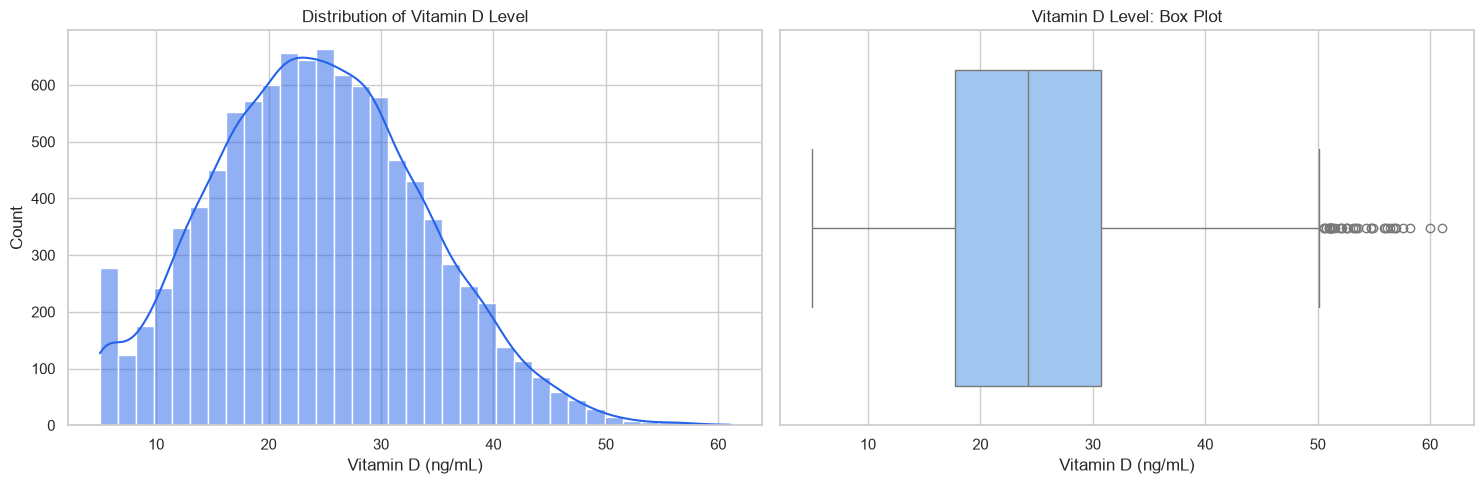

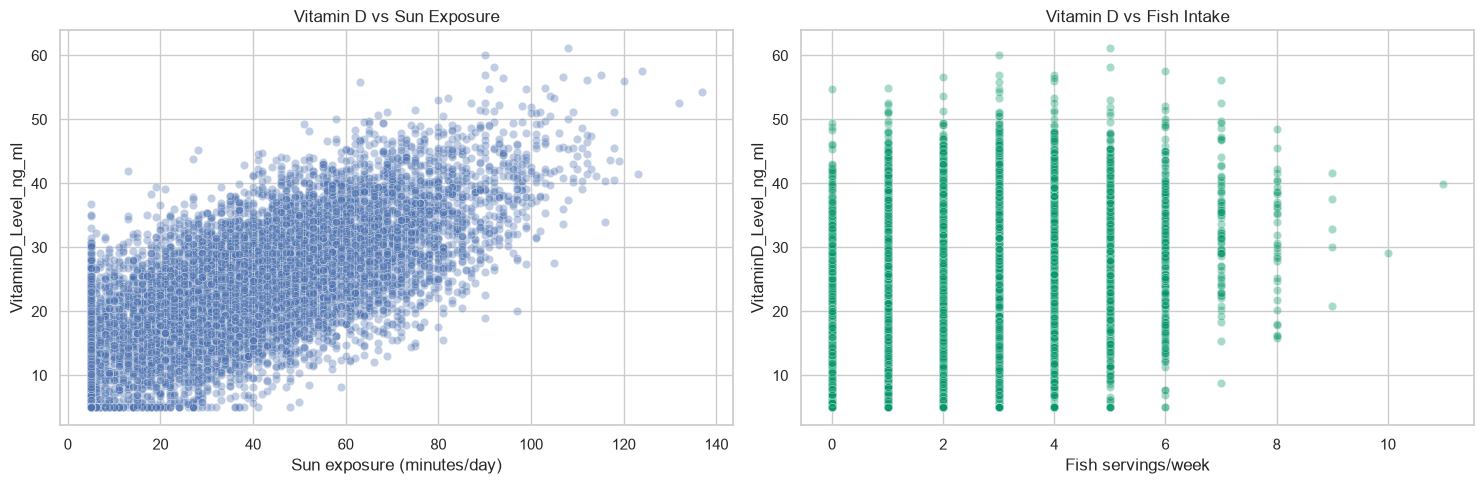

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(target, bins=35, kde=True, color='#2563eb', ax=axes[0])
axes[0].set(title='Distribution of Vitamin D Level', xlabel='Vitamin D (ng/mL)')
sns.boxplot(x=target, color='#93c5fd', ax=axes[1])
axes[1].set(title='Vitamin D Level: Box Plot', xlabel='Vitamin D (ng/mL)')
plt.tight_layout()
plt.show()

eda_frame = features.copy()
eda_frame[TARGET_COLUMN] = target
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=eda_frame, x='Sun_Exposure_min', y=TARGET_COLUMN, alpha=0.35, ax=axes[0])
axes[0].set(title='Vitamin D vs Sun Exposure', xlabel='Sun exposure (minutes/day)')
sns.scatterplot(data=eda_frame, x='Fish_intake_week', y=TARGET_COLUMN, alpha=0.35, ax=axes[1], color='#059669')
axes[1].set(title='Vitamin D vs Fish Intake', xlabel='Fish servings/week')
plt.tight_layout()
plt.show()

## 4. Correlation analysis

Correlation is calculated only for numeric, non-leakage features and the regression target. It is an EDA aid, not a model selection rule.

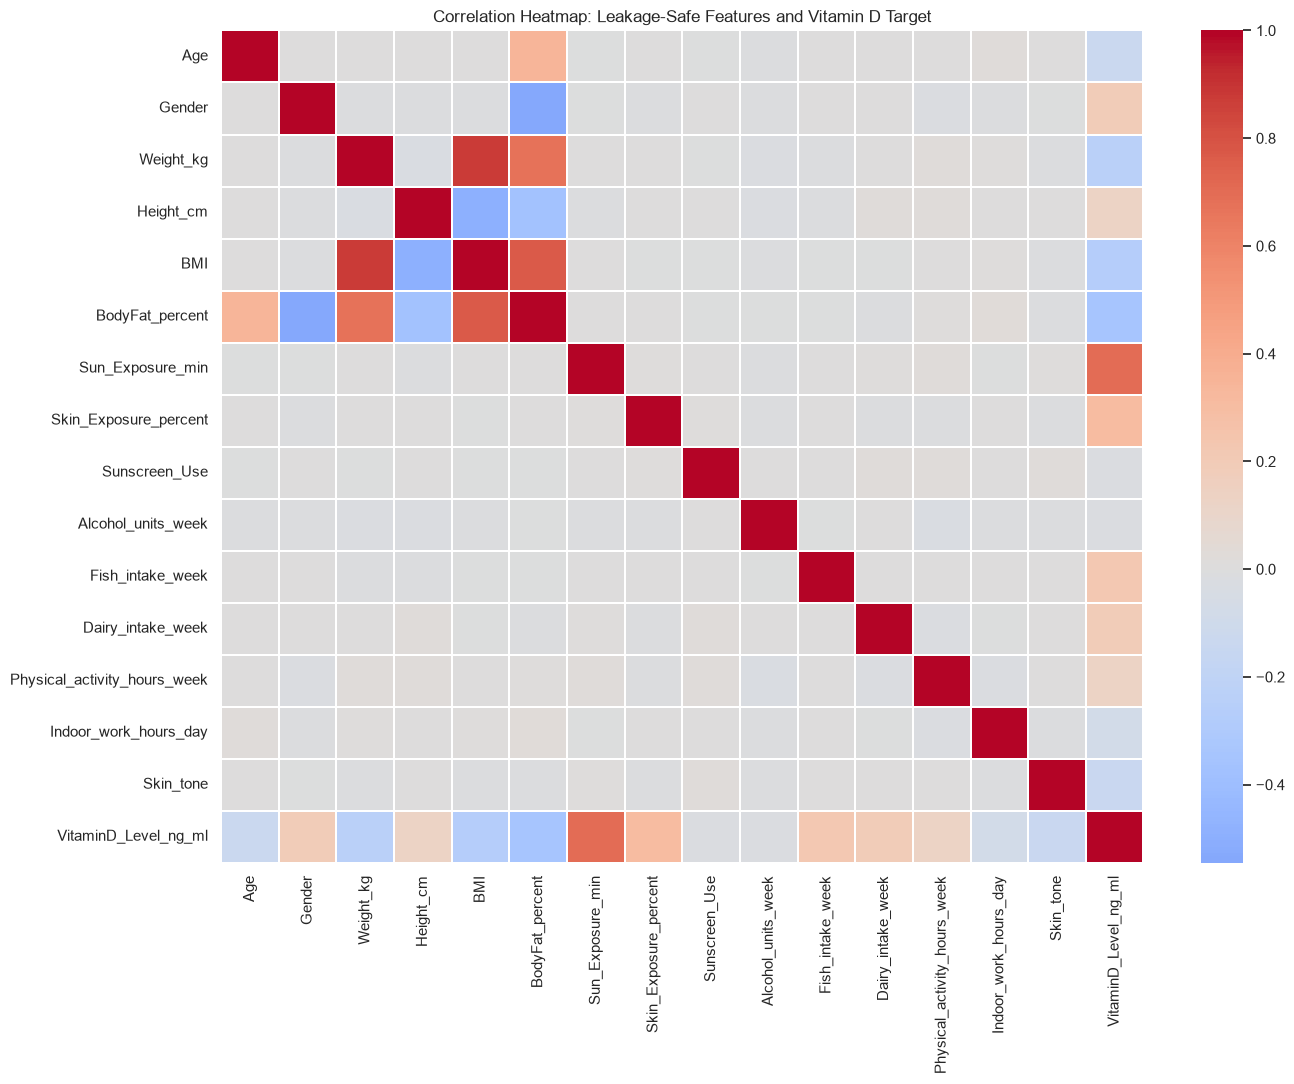

,correlation_with_vitamin_d
BodyFat_percent,-0.350948
BMI,-0.267232
Weight_kg,-0.238475
Skin_tone,-0.140962
Age,-0.132071
Indoor_work_hours_day,-0.075743
Sunscreen_Use,-0.017500
Alcohol_units_week,-0.015045
Height_cm,0.126959
Physical_activity_hours_week,0.128456


In [5]:
numeric_eda = eda_frame.select_dtypes(include='number')
correlation = numeric_eda.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(correlation, cmap='coolwarm', center=0, square=False, linewidths=0.25)
plt.title('Correlation Heatmap: Leakage-Safe Features and Vitamin D Target')
plt.tight_layout()
plt.show()

target_correlations = correlation[TARGET_COLUMN].drop(TARGET_COLUMN).sort_values()
display(target_correlations.to_frame('correlation_with_vitamin_d'))

## 5. Reproducible model comparison

The production training script uses an 80/20 held-out split with `random_state=42`, then five-fold shuffled cross-validation on the training portion. It compares Linear Regression, Random Forest, XGBoost, and CatBoost.

To avoid conflicting results and accidental artifact overwrites, this notebook reads the already-generated report rather than refitting and saving models. `build_models(features)` is displayed below to show the exact model set used.

In [6]:
models = build_models(features)
print('Models:', list(models))
if not METRICS_PATH.exists():
    raise FileNotFoundError('reports/model_metrics.csv is missing. Run `python -m src.train` from the project root.')
metrics = pd.read_csv(METRICS_PATH)
display(metrics.style.format({column: '{:.3f}' for column in metrics.columns if column != 'model'}))

Models: ['Linear Regression', 'Random Forest', 'XGBoost', 'CatBoost']


,model,cv_r2_mean,cv_r2_std,cv_mae_mean,cv_rmse_mean,test_r2,test_mae,test_rmse
0,Linear Regression,0.824,0.004,3.155,3.958,0.813,3.202,4.004
1,Random Forest,0.771,0.002,3.602,4.515,0.762,3.614,4.513
2,CatBoost,0.767,0.002,3.660,4.556,0.762,3.623,4.515
3,XGBoost,0.744,0.001,3.840,4.775,0.736,3.817,4.756


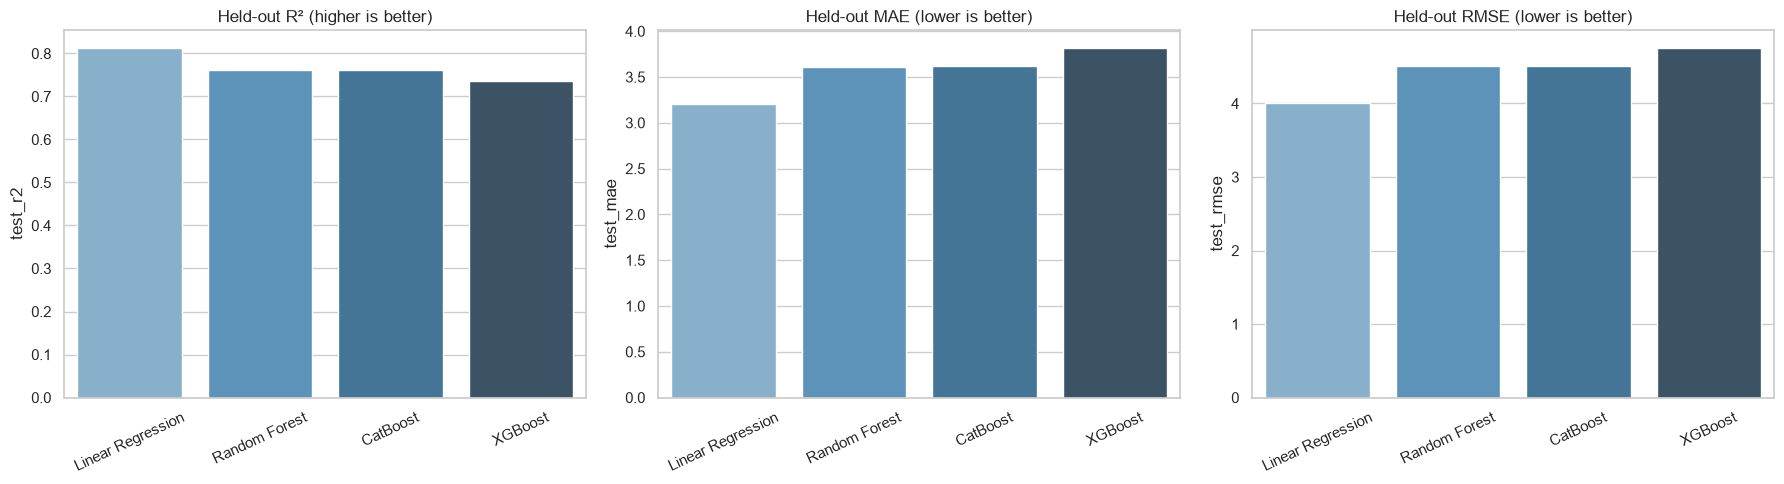

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, column, title in zip(axes, ['test_r2', 'test_mae', 'test_rmse'], ['Held-out R² (higher is better)', 'Held-out MAE (lower is better)', 'Held-out RMSE (lower is better)']):
    sns.barplot(data=metrics, x='model', y=column, hue='model', legend=False, palette='Blues_d', ax=axis)
    axis.set(title=title, xlabel='')
    axis.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

## 6. Held-out prediction diagnostics

The saved report contains predictions for the untouched test set produced by the same training run. The best model selected by cross-validation is loaded only for inspection; no artifact is modified.

In [8]:
if not PREDICTIONS_PATH.exists() or not MODEL_PATH.exists() or not METADATA_PATH.exists():
    raise FileNotFoundError('Saved reports or model are missing. Run `python -m src.train` from the project root.')
predictions = pd.read_csv(PREDICTIONS_PATH)
metadata = json.loads(METADATA_PATH.read_text(encoding='utf-8'))
saved_model = joblib.load(MODEL_PATH)
best_model_name = metadata['best_model']
best_prediction_column = f"{best_model_name.lower().replace(' ', '_')}_prediction"
actual = predictions['actual_vitamin_d_ng_ml']
predicted = predictions[best_prediction_column]
residuals = actual - predicted
print('Saved best model:', best_model_name)
print(metadata['evaluation'])
print(metadata['data_label'])

Saved best model: Linear Regression
Five-fold shuffled CV on the training split; final metrics use an untouched 20% holdout.
Custom CSV supplied from the original repository; synthetic status is not documented.


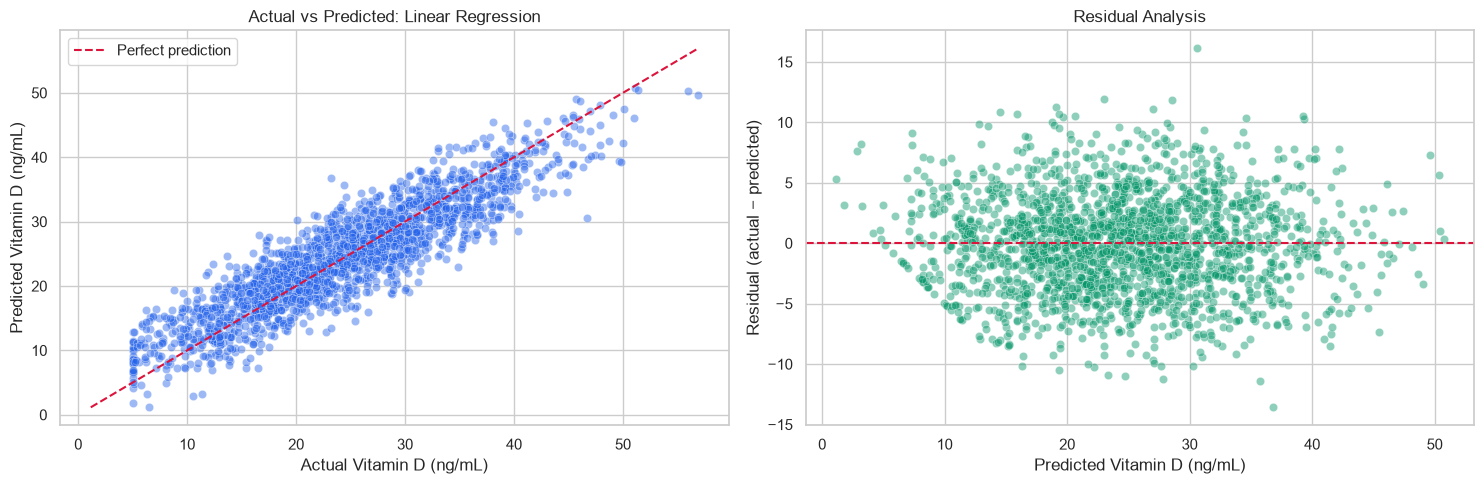

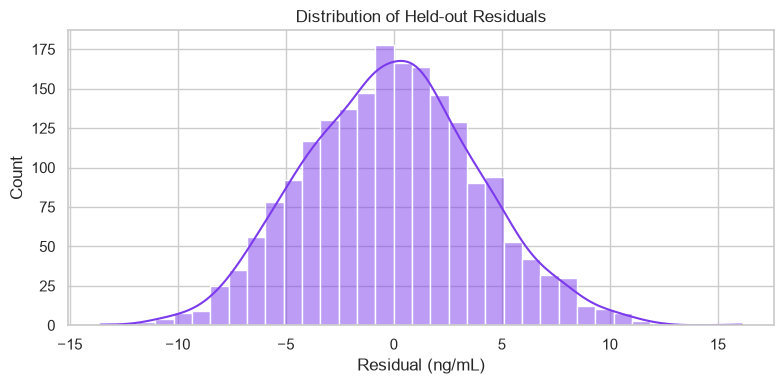

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(x=actual, y=predicted, alpha=0.45, ax=axes[0], color='#2563eb')
limits = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
axes[0].plot(limits, limits, '--', color='crimson', label='Perfect prediction')
axes[0].set(title=f'Actual vs Predicted: {best_model_name}', xlabel='Actual Vitamin D (ng/mL)', ylabel='Predicted Vitamin D (ng/mL)')
axes[0].legend()
sns.scatterplot(x=predicted, y=residuals, alpha=0.45, ax=axes[1], color='#059669')
axes[1].axhline(0, color='crimson', linestyle='--')
axes[1].set(title='Residual Analysis', xlabel='Predicted Vitamin D (ng/mL)', ylabel='Residual (actual − predicted)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.histplot(residuals, bins=35, kde=True, color='#7c3aed')
plt.title('Distribution of Held-out Residuals')
plt.xlabel('Residual (ng/mL)')
plt.tight_layout()
plt.show()

## 7. Presentation summary

- The model comparison uses a fixed train/test split and five-fold cross-validation inside the training data.
- Target-derived labels are excluded before modeling, so they cannot inflate the reported scores.
- The saved best pipeline includes both preprocessing and the fitted estimator.
- These results apply only to this custom dataset. A credible clinical claim would require a documented, representative external dataset and independent validation.